In [ ]:
# Exploratory Data Analysis (EDA)
## Korean Beauty Product Customer Reviews


In [ ]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving korean_beauty_reviews_cleaned.csv to korean_beauty_reviews_cleaned.csv


In [ ]:
import pandas as pd

df = pd.read_csv("korean_beauty_reviews_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)


Dataset loaded successfully!
Dataset Shape: (92590, 7)


In [ ]:
df.head()

,source_id,product_name,rating,skin_type,review,cleaned_review,sentiment
0,1,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,복합성,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Positive
1,2,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,복합성,"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...","👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...",Positive
2,3,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,복합성,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름...,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름 ...,Positive
3,4,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,지성,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,Positive
4,5,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,복합성,"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...","닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...",Positive


In [ ]:
print("Total Reviews:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

Total Reviews: 92590
Total Columns: 7
Dataset Shape: (92590, 7)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92590 entries, 0 to 92589
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   source_id       92590 non-null  int64 
 1   product_name    92590 non-null  object
 2   rating          92590 non-null  int64 
 3   skin_type       92590 non-null  object
 4   review          92590 non-null  object
 5   cleaned_review  92590 non-null  object
 6   sentiment       92590 non-null  object
dtypes: int64(2), object(5)
memory usage: 4.9+ MB


In [ ]:
df.describe(include="all")

,source_id,product_name,rating,skin_type,review,cleaned_review,sentiment
count,92590.000000,92590,92590.000000,92590,92590,92590,92590
unique,NaN,351,NaN,23,92590,92590,3
top,NaN,[단독기획] 구달 청귤 비타C 잡티 톤업 크림 (본품50ml+5ml+세럼 5ml 증정),NaN,Unknown,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Positive
freq,NaN,1067,NaN,68116,1,1,87435
mean,58989.629668,NaN,4.718587,NaN,NaN,NaN,NaN
std,37418.698801,NaN,0.641442,NaN,NaN,NaN,NaN
min,1.000000,NaN,1.000000,NaN,NaN,NaN,NaN
25%,26388.250000,NaN,5.000000,NaN,NaN,NaN,NaN
50%,54738.500000,NaN,5.000000,NaN,NaN,NaN,NaN
75%,90408.750000,NaN,5.000000,NaN,NaN,NaN,NaN


In [ ]:
total_products = df["product_name"].nunique()
print("Total Unique Beauty Products:", total_products)

Total Unique Beauty Products: 351


In [ ]:
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
source_id         0
product_name      0
rating            0
skin_type         0
review            0
cleaned_review    0
sentiment         0
dtype: int64


In [ ]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print("Missing Values Percentage:")
print(missing_percentage.round(2))

Missing Values Percentage:
source_id         0.0
product_name      0.0
rating            0.0
skin_type         0.0
review            0.0
cleaned_review    0.0
sentiment         0.0
dtype: float64


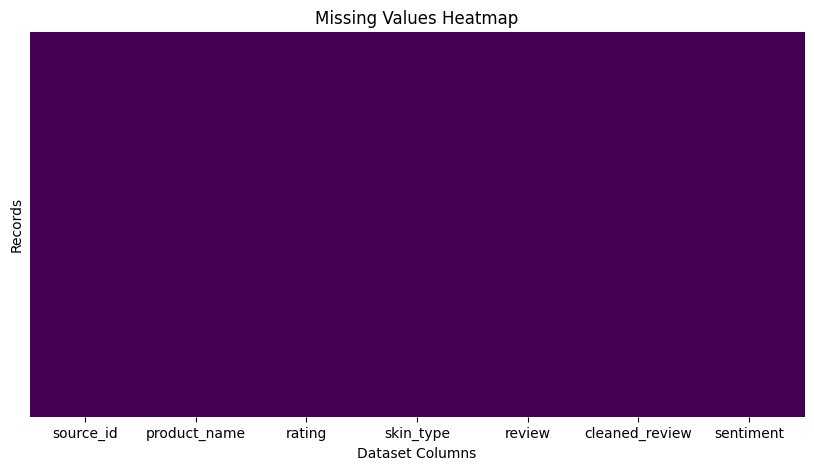

In [ ]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.xlabel("Dataset Columns")
plt.ylabel("Records")

plt.show()

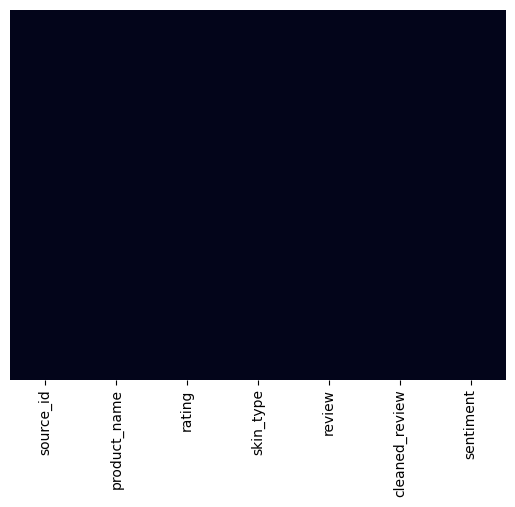

In [ ]:
## OPTIONAL CELL

sns.heatmap(
    df.sample(min(1000, len(df)), random_state=42).isnull(),
    cbar=False,
    yticklabels=False
)
plt.show()

In [ ]:
rating_counts = df["rating"].value_counts().sort_index()

print("Rating Distribution:")
print(rating_counts)

Rating Distribution:
rating
1      639
2      668
3     3848
4    13800
5    73635
Name: count, dtype: int64


In [ ]:
rating_percentage = (
    df["rating"].value_counts(normalize=True).sort_index()
) * 100

print("Rating Percentage:")
print(rating_percentage.round(2))

Rating Percentage:
rating
1     0.69
2     0.72
3     4.16
4    14.90
5    79.53
Name: proportion, dtype: float64


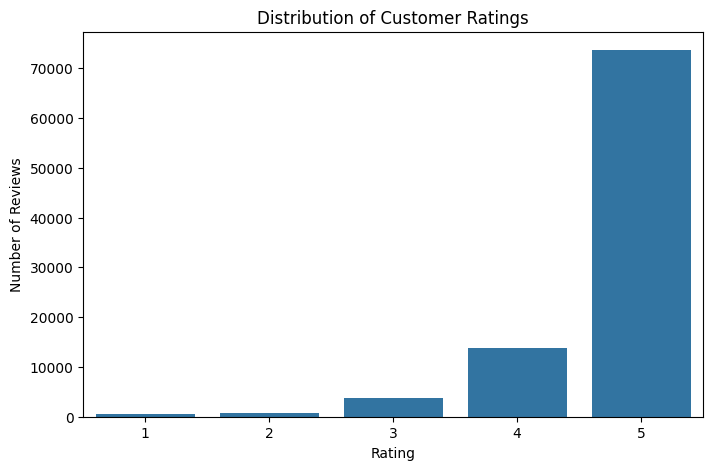

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rating",
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
average_rating = df["rating"].mean()
print("Overall Average Rating:", round(average_rating, 2))

Overall Average Rating: 4.72


In [ ]:
skin_counts = df["skin_type"].value_counts()

print("Skin Type Distribution:")
print(skin_counts)

Skin Type Distribution:
skin_type
Unknown    68116
복합성        12131
건성          7052
지성          3245
민감성         1052
트러블성         397
중성           141
웜톤           118
쿨톤           106
약건성          100
모공            45
각질            31
미백            18
여름쿨톤           7
블랙헤드           6
트러블            6
겨울쿨톤           6
가을웜톤           4
아토피            2
봄웜톤            2
다크서클           2
잡티             2
주름             1
Name: count, dtype: int64


In [ ]:
skin_percentage = (
    df["skin_type"].value_counts(normalize=True)
) * 100

print("Skin Type Percentage:")
print(skin_percentage.round(2))

Skin Type Percentage:
skin_type
Unknown    73.57
복합성        13.10
건성          7.62
지성          3.50
민감성         1.14
트러블성        0.43
중성          0.15
웜톤          0.13
쿨톤          0.11
약건성         0.11
모공          0.05
각질          0.03
미백          0.02
여름쿨톤        0.01
블랙헤드        0.01
트러블         0.01
겨울쿨톤        0.01
가을웜톤        0.00
아토피         0.00
봄웜톤         0.00
다크서클        0.00
잡티          0.00
주름          0.00
Name: proportion, dtype: float64


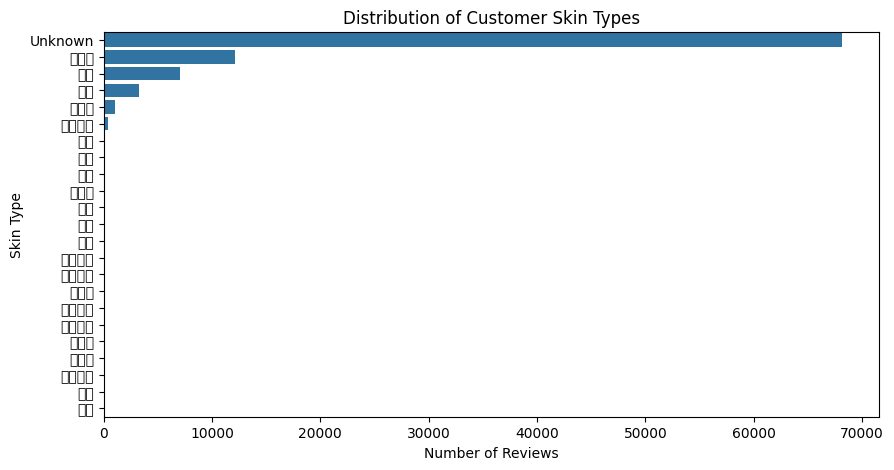

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y="skin_type",
    order=df["skin_type"].value_counts().index
)

plt.title("Distribution of Customer Skin Types")
plt.xlabel("Number of Reviews")
plt.ylabel("Skin Type")

plt.show()

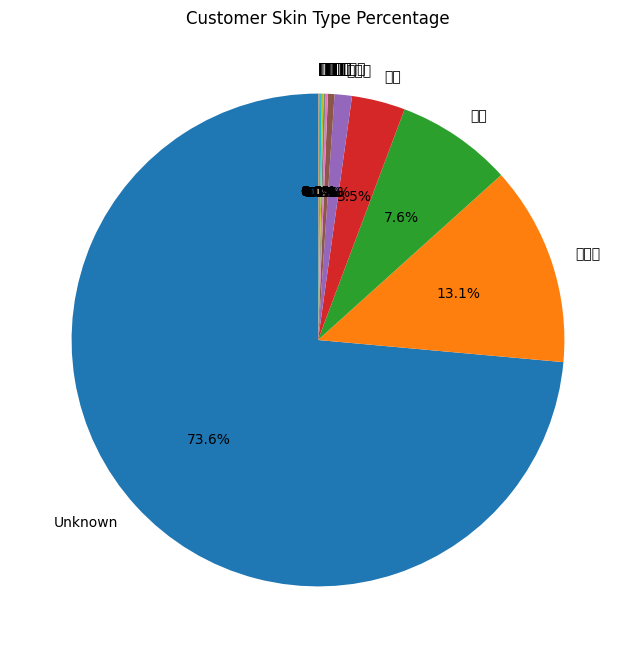

In [ ]:
plt.figure(figsize=(8, 8))

skin_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Skin Type Percentage")
plt.ylabel("")

plt.show()

In [ ]:
print("=" * 45)
print("KOREAN BEAUTY REVIEWS - EDA SUMMARY")
print("=" * 45)

print("Total Reviews:", len(df))

print("Total Products:", df["product_name"].nunique())

print("Total Columns:", len(df.columns))

print("Average Rating:", round(df["rating"].mean(), 2))

print("\nRating Distribution:")
print(df["rating"].value_counts().sort_index())

print("\nSkin Type Distribution:")
print(df["skin_type"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

print("=" * 45)


KOREAN BEAUTY REVIEWS - EDA SUMMARY
Total Reviews: 92590
Total Products: 351
Total Columns: 7
Average Rating: 4.72

Rating Distribution:
rating
1      639
2      668
3     3848
4    13800
5    73635
Name: count, dtype: int64

Skin Type Distribution:
skin_type
Unknown    68116
복합성        12131
건성          7052
지성          3245
민감성         1052
트러블성         397
중성           141
웜톤           118
쿨톤           106
약건성          100
모공            45
각질            31
미백            18
여름쿨톤           7
블랙헤드           6
트러블            6
겨울쿨톤           6
가을웜톤           4
아토피            2
봄웜톤            2
다크서클           2
잡티             2
주름             1
Name: count, dtype: int64

Missing Values:
source_id         0
product_name      0
rating            0
skin_type         0
review            0
cleaned_review    0
sentiment         0
dtype: int64
